# Checkpoint 3

Estimating slow conduction in cardiac tissue is a key inverse problem in cardiac electrophysiology. In this checkpoint, the goal is to reconstruct a **spatially varying slow-conduction field** from electrogram-derived activation times (see Checkpoint 1).

We use the **eikonal equation**, which models activation time as a function of spatial position and local conduction velocity. This formulation enables efficient forward simulations and is well suited for PDE-constrained optimization, physics-informed neural networks, and data-driven approaches.
The objective is to estimate a continuous conduction velocity map by minimizing the discrepancy between simulated and observed activation times, capturing both the location and severity of conduction slowing.

In this checkpoint 3, the anisotropy ratio will be fixed to 3.0 for all patients.

In [47]:
# imports

import numpy as np
import matplotlib.pyplot as plt


# Physics-based model implementation

Implemenatation of the algorithm presented in :

Sermesant, Maxime, et al. "An anisotropic multi-front fast marching method for real-time simulation of cardiac electrophysiology." Functional Imaging and Modeling of the Heart: 4th International Conference, FIHM 2007, Salt Lake City, UT, USA, June 7-9, 2007. Proceedings 4. Springer Berlin Heidelberg, 2007.

In [48]:
import numpy as np
import heapq

def anisotropic_FMM_GPT(
    x0, y0, t0,
    X, Y,
    speed_input,
    sigma_11, sigma_12, sigma_22,
    N_edge=None
):
    """
    Fast-marching style solver with anisotropy and spatially varying speed.

    Parameters
    ----------
    x0, y0 : float
        Initial source location.
    t0 : float
        Initial activation time.
    X, Y : 2D ndarray
        Grid coordinates.
    speed_input : float, callable, or 2D ndarray
        Can be:
        - a scalar: constant speed everywhere
        - a function: speed_input(x, y)
        - a 2D array with same shape as X, Y
    sigma_11, sigma_12, sigma_22 : float
        Components of the inverse of conductivity tensor.
    N_edge : int or None
        Optional. If None, inferred from grid shape.

    Returns
    -------
    T_final : 2D ndarray
        Arrival time map.
    """

    nrows, ncols = X.shape
    if N_edge is None:
        N_edge = nrows - 1

    INF = 1e4
    P = np.linspace(0.0, 1.0, 11)

    # nearest grid node to source
    j0 = np.abs(X[0, :] - x0).argmin()
    i0 = np.abs(Y[:, 0] - y0).argmin()

    T = np.full((nrows, ncols), INF, dtype=float)
    T_final = np.full((nrows, ncols), INF, dtype=float)

    T[i0, j0] = t0
    T_final[i0, j0] = t0

    known = np.zeros((nrows, ncols), dtype=bool)

    # min-heap of (arrival_time, i, j)
    heap = [(t0, i0, j0)]

    def get_speed(i, j, x, y):
        if callable(speed_input):
            val = speed_input(x, y)
        elif np.isscalar(speed_input):
            val = speed_input
        else:
            val = speed_input[i, j]

        if val <= 0:
            raise ValueError(f"Speed must be positive. Got {val} at ({i}, {j}).")
        return val

    def metric_dist(xa, ya, xb, yb, speed_val):
        dx = xa - xb
        dy = ya - yb
        return np.sqrt(
            sigma_11 * dx * dx +
            2.0 * sigma_12 * dx * dy +
            sigma_22 * dy * dy
        ) / speed_val

    def update_fun(
        T_xi, T_x, T_y,
        X_xi, X_x, X_y,
        Y_xi, Y_x, Y_y,
        flag_known,
        i_xi, j_xi
    ):
        speed_val = get_speed(i_xi, j_xi, X_xi, Y_xi)

        if flag_known:
            dx = P * (X_xi - X_x) + (1.0 - P) * (X_xi - X_y)
            dy = P * (Y_xi - Y_x) + (1.0 - P) * (Y_xi - Y_y)

            triangle_vals = (
                P * T_x + (1.0 - P) * T_y
                + np.sqrt(
                    sigma_11 * dx * dx +
                    2.0 * sigma_12 * dx * dy +
                    sigma_22 * dy * dy
                ) / speed_val
            )
            cand = triangle_vals.min()
        else:
            cand = T_x + metric_dist(X_xi, Y_xi, X_x, Y_x, speed_val)

        return min(T_xi, cand)

    # side nodes used for triangle updates
    side_map = {
        (-1,  0): [(-1, +1), (-1, -1)],  # north
        (+1,  0): [(+1, +1), (+1, -1)],  # south
        ( 0, -1): [(+1, -1), (-1, -1)],  # west
        ( 0, +1): [(+1, +1), (-1, +1)],  # east
    }

    while heap:
        t_sel, i_sel, j_sel = heapq.heappop(heap)

        # ignore stale entries
        if known[i_sel, j_sel]:
            continue
        if t_sel > T_final[i_sel, j_sel]:
            continue

        known[i_sel, j_sel] = True

        # visit 4-neighbors
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, +1)]:
            ni, nj = i_sel + di, j_sel + dj

            if not (0 <= ni < nrows and 0 <= nj < ncols):
                continue
            if known[ni, nj]:
                continue

            new_T = INF

            for sdi, sdj in side_map[(di, dj)]:
                si, sj = i_sel + sdi, j_sel + sdj

                if not (0 <= si < nrows and 0 <= sj < ncols):
                    continue

                new_T = update_fun(
                    T_xi=new_T,
                    T_x=T_final[i_sel, j_sel],
                    T_y=T_final[si, sj],
                    X_xi=X[ni, nj], X_x=X[i_sel, j_sel], X_y=X[si, sj],
                    Y_xi=Y[ni, nj], Y_x=Y[i_sel, j_sel], Y_y=Y[si, sj],
                    flag_known=known[si, sj],
                    i_xi=ni, j_xi=nj
                )

            if new_T < T_final[ni, nj]:
                T[ni, nj] = new_T
                T_final[ni, nj] = new_T
                heapq.heappush(heap, (new_T, ni, nj))

    return T_final

# Eikonal equation

Let us consider the Eikonal model: find T(x,y)

\begin{aligned}
  & 80 \sqrt{ \nabla T(x,y) D \nabla T(x,y)} = 1  \,, \quad (x,y) \in [-2,2] \times [-2,2]\,,\\
  & u(x,y) = t_0,t_1  \,, \qquad \qquad \qquad \qquad \qquad x=x_0,x_1,y=y_0,y_1 \,, \\
\end{aligned}

where 
\begin{aligned}
D = 1\ \vec{b} \otimes \vec{b} + \frac{1}{a_{ratio}}  \ \vec{a} \otimes \vec{a},
\end{aligned}
being $ \vec{b} $ the given fiber orientation and $ \vec{a} $ the given cross-fiber orientation (orthogonal to $ \vec{b}$).

The unknown parameters of the problem are: 
- conduction velocity (tissue property common to all the patients),
- anisotropy ratio $a_{ratio}$ (tissue property common to all the patients),
- the slow conduction positions $(x_{SC},y_{SC})$ and its radius $r_{SC}$.

In [49]:
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0,2.0,401), np.linspace(-2.0,2.0,401))

x0 = -1.5
y0 = -1

theta_fiber = 0
a_ratio = 5

theta0 = np.pi/2 - theta_fiber
a = np.array([np.cos(theta0), np.sin(theta0)]).T
b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
print(D)

D_inv = np.linalg.inv(D)
sigma_11 = D_inv[0][0]
sigma_12 = D_inv[0][1]
sigma_21 = D_inv[1][0]
sigma_22 = D_inv[1][1]

xc, yc = 0.5, 0.5
r = 0.5

speed_field = lambda x, y: 20.0 if (x - xc)**2 + (y - yc)**2 <= r**2 else 80.0

activation_time = anisotropic_FMM_GPT( x0 , y0 , 0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )




[[1.0000000e+00 1.2246468e-17]
 [1.2246468e-17 2.0000000e-01]]


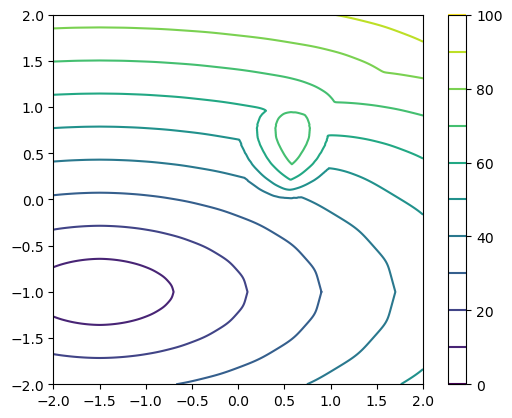

In [50]:

plt.contour(X_mesh, Y_mesh, activation_time*1000 , 10) 
plt.gca().set_aspect(1)
plt.colorbar()

In [51]:
N_samples = 1

np.random.seed(32)

measurements_dataset = []
groundtruth_dataset = []

for i_sample in range(N_samples):

    x0 = np.random.uniform(low=1.5,high=1.5)
    y0 = np.random.uniform(low=-1.5,high=1.5)
    x1 = np.random.uniform(low=1.5,high=1.5)
    y1 = np.random.uniform(low=-1.5,high=1.5)
    theta_fiber = 0.0
    a_ratio = np.random.uniform(low=1,high=9)

    theta0 = np.pi/2 - theta_fiber
    a = np.array([np.cos(theta0), np.sin(theta0)]).T
    b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

    D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
    print(D)

    D_inv = np.linalg.inv(D)
    sigma_11 = D_inv[0][0]
    sigma_12 = D_inv[0][1]
    sigma_21 = D_inv[1][0]
    sigma_22 = D_inv[1][1]

    # compute activation time
    activation_time = anisotropic_FMM_GPT( x0 , y0 , 0.0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )

    # rescaling in ms
    activation_time = activation_time*1e3

    # measurements location
    Spline_spacing = [0.5, 0.7, 1.3, 1.5]
    Angles_spacing =  [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5 ]
    
    index_extracted = []
    x_meas = []
    y_meas = []
    time_meas = []

    for i in range(4):
        #print(i)
        for j in range(5):
            #print(j)
            MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]) )**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]) )**2
            [i_sel, j_sel] = np.unravel_index(MeasMat.argmin(), MeasMat.shape) 
            index_extracted.append(i_sel)
            x_meas.append(X_mesh[i_sel,j_sel])
            y_meas.append(Y_mesh[i_sel,j_sel])
            time_meas.append(activation_time[i_sel,j_sel])

    measurements_dataset.append( [ x_meas, y_meas, time_meas ] )
    groundtruth_dataset.append([activation_time])

[[1.00000000e+00 8.88280440e-18]
 [8.88280440e-18 1.45067205e-01]]


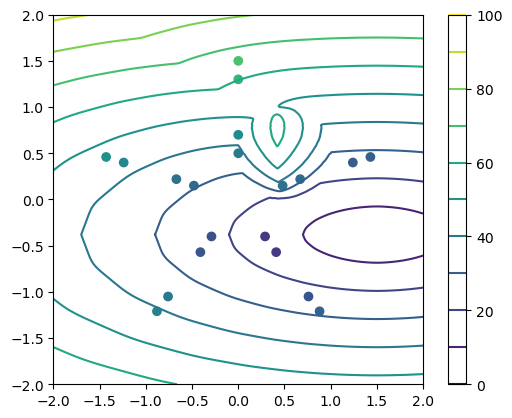

In [52]:
plt.figure(1)
plt.scatter( x_meas, y_meas, c=time_meas, vmin= 0, vmax=np.max(activation_time) )
plt.contour(X_mesh, Y_mesh, activation_time , 10)
plt.gca().set_aspect(1)
plt.colorbar()

# Checkpoint 3

Implement your algorithm to process the traces of the 20 unipolar electrogram signals and identify the center and radius of the slow conduction region.

The algorithm must return the following outputs:

1. **slow conduction fields evaluated on a 16x16 grid** 


Provide your algorithm's implementation in this notebook usign the signature defined below.

In [53]:
# load data
signals_part1 = np.load('checkpoint3dataset.npy')

signals_part2 = np.load('checkpoint3dataset_p2.npy')

# 3. Accoda i due array lungo il primo asse (axis=0)
# Questo creerà un unico array che contiene tutti gli eventi
signals = np.concatenate((signals_part1, signals_part2), axis=0)

# select event to be display
ind_event = 24

signals_event = signals[ind_event,:,:]

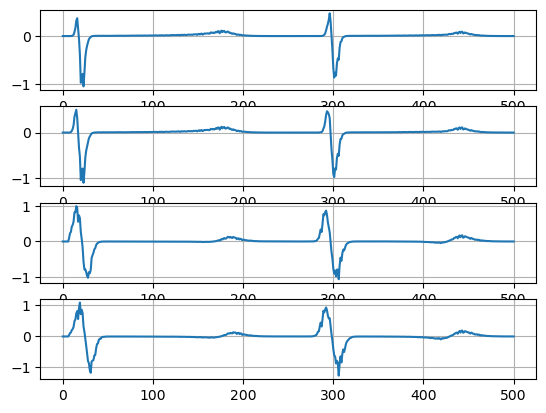

In [54]:
# select a spline (options: 0,1,2,3,4)
ind_spline = 0
# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

In [55]:
def load_and_plot_velocity_fields(
    filename,
    sim_idx=0,
    N=None,
    M=None,
    h=None
):
    velocity_fields = np.load(filename)

    field16 = velocity_fields[sim_idx]

    if N is not None and M is not None and h is not None:
        step_x = N // 16
        step_y = M // 16

        ix = np.arange(0, step_x * 16, step_x)
        iy = np.arange(0, step_y * 16, step_y)

        Lx_sub = ix[-1] * h
        Ly_sub = iy[-1] * h

        extent = [0, Lx_sub, 0, Ly_sub]
    else:
        extent = None

    plt.figure(figsize=(5, 4))
    plt.imshow(
        field16.T,
        origin='lower',
        extent=extent,
        cmap='viridis',
        aspect='equal'
    )
    plt.colorbar(label='Conduction scale')
    plt.title(f'Case {sim_idx} - velocity field (16x16)')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.tight_layout()
    plt.show()

In [56]:
import numpy as np

# Carica le due parti del dataset delle velocità
v_fields_part1 = np.load("checkpoint3velocityfield16.npy")
v_fields_part2 = np.load("checkpoint3velocityfield16_p2.npy") # Sostituisci con il nome reale del secondo file

# Uniscili in un unico array
# Se sono 25 scenari totali, v_fields avrà shape (25, 16, 16)
v_fields_total = np.concatenate((v_fields_part1, v_fields_part2), axis=0)

# Salva l'array unito in un file temporaneo o passalo direttamente se modifichi la funzione
np.save("velocity_fields_complete.npy", v_fields_total)



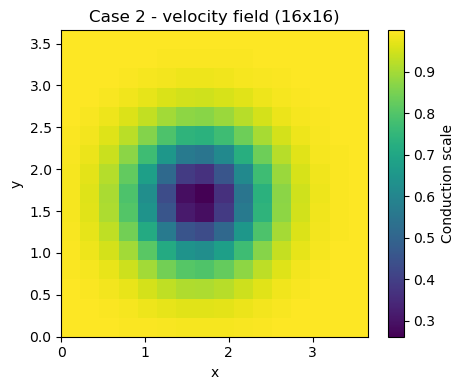

In [57]:
N = np.int32(2*164)
M = np.int32(2*164)
h = 4.0/N
load_and_plot_velocity_fields("velocity_fields_complete.npy", sim_idx=2,N=N,M=M,h=h)


In [60]:
#Load dati
focal_p1=np.load("checkpoint3FocalPoints.npy")
focal_p2=np.load("checkpoint3FocalPoints_p2.npy")
focal_points = np.concatenate((focal_p1, focal_p2), axis=0)

starting_point_p1=np.load("checkpoint3starting.npy")
starting_point_p2=np.load("checkpoint3starting_p2.npy")
starting_points = np.concatenate((starting_point_p1, starting_point_p2), axis=0)

anisotropy_p1=np.load("checkpoint3anisotropy.npy")
anisotropy_p2=np.load("checkpoint3anisotropy_p2.npy")
anisotropy = np.concatenate((anisotropy_p1, anisotropy_p2), axis=0)

#I valori qui sotto vengono dal CKP2, se cambiano i risultati, vanno cambiati!
v_base=67.96
v_slow=19.80

print("signals shape  :", signals.shape)   
print("focal shape    :", focal_points.shape)
print("starting shape :", starting_points.shape)
print("anisotropy     :", anisotropy.shape)


signals shape  : (25, 20, 501)
focal shape    : (25, 2, 2)
starting shape : (25, 2)
anisotropy     : (25, 1)


In [61]:
# ==========================================
# MODULO DI ESTRAZIONE E ALLINEAMENTO TOPOLOGICO
# ==========================================
import numpy as np
from scipy.signal import argrelextrema, savgol_filter

def GroupSolutionCP1(signals_event):
    """
    Identifica il millisecondo di attivazione locale tramite il minimo del gradiente.
    (Versione originale Checkpoint 1)
    """
    sig_filtered = savgol_filter(signals_event, window_length=11, polyorder=3, axis=1)
    n_sensors = sig_filtered.shape[0]
    timings = []
    min_dist = 100 
    
    for i in range(n_sensors):
        ds = np.gradient(sig_filtered[i, :])
        min_indices = argrelextrema(ds, np.less)[0]
        
        selected = []
        if len(min_indices) > 0:
            depths = ds[min_indices]
            sorted_args = np.argsort(depths)
            candidates = min_indices[sorted_args]
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            selected.sort()

        row_time = [None, None]
        for j in range(min(len(selected), 2)):
            row_time[j] = int(selected[j])
        
        row_final = [t if t is not None else np.nan for t in row_time]
        timings.append(row_final)

    return timings

def extract_and_align_timings(signals_event):
    """
    Riordina radialmente i sensori e converte i tempi assoluti in tempi relativi.
    Output pronto per il calcolo della Loss Function.
    """
    raw_timings = GroupSolutionCP1(signals_event)
    
    t_beat1_ordered = []
    t_beat2_ordered = []
    
    # 1. Correzione Topologica: Le misurazioni avvengono su 5 spline da 4 sensori.
    # L'array grezzo ha una direzione radiale opposta rispetto alla mesh spaziale calcolata.
    for s in range(5):
        # Estraiamo la singola spline e ne invertiamo l'ordine
        spline_chunk_reversed = raw_timings[s*4 : (s+1)*4][::-1] 
        
        for t in spline_chunk_reversed:
            t_beat1_ordered.append(t[0])
            t_beat2_ordered.append(t[1])

    meas_beat1 = np.array(t_beat1_ordered, dtype=float)
    meas_beat2 = np.array(t_beat2_ordered, dtype=float)
    
    # 2. Isolamento del Ritardo Iniziale (Tempi Relativi)
    # Sottraendo il minimo, rendiamo il vettore indipendente dall'offset di stimolo (t0, t1)
    # che l'Eikonale non può conoscere a priori in questa fase.
    meas_beat1 = meas_beat1 - np.nanmin(meas_beat1)
    meas_beat2 = meas_beat2 - np.nanmin(meas_beat2)
    
    return meas_beat1, meas_beat2

In [62]:
# ==========================================
# CELLA 3: GEOMETRIA E INTERPOLATORE SPAZIALE
# ==========================================
# 1. Griglia Densa (Fisica Eikonale 201x201)
N_dense = 201
x_dense = np.linspace(-2.0, 2.0, N_dense)
X_mesh_vel, Y_mesh_vel = np.meshgrid(x_dense, x_dense)

# Posizioni dei sensori sulla griglia densa
Spline_spacing = [0.5, 0.7, 1.3, 1.5]
Angles_spacing = [np.pi/10.0, np.pi/10.0+2*np.pi/5, np.pi/10.0+4*np.pi/5, np.pi/10.0+6*np.pi/5, np.pi/10.0+8*np.pi/5]

idx_vel = []
for j in range(5):
    for i in range(4):
        MeasMat = (X_mesh_vel - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh_vel - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        idx_vel.append(np.unravel_index(MeasMat.argmin(), MeasMat.shape))
idx_vel = np.array(idx_vel)

# 2. Griglia Sparsa (Ottimizzazione Parametrica)
N_coarse = 8 # 64 nodi di controllo
x_coarse = np.linspace(-2.0, 2.0, N_coarse)

def generate_dense_field(v_coarse_flat):
    """Espande i 64 parametri nella mappa continua 201x201"""
    v_coarse_2d = v_coarse_flat.reshape((N_coarse, N_coarse))
    interpolator = RectBivariateSpline(x_coarse, x_coarse, v_coarse_2d)
    speed_grid = interpolator(x_dense, x_dense)
    return np.clip(speed_grid, 5.0, 150.0) # Vincolo di realtà fisica

In [63]:
# ==========================================
# CELLA 4: FUNZIONE OBIETTIVO E REGOLARIZZAZIONE
# ==========================================
def evaluate_patient(idx_patient, v_coarse_flat, lambda_reg=15.0):
    """
    Calcola il costo per un paziente specifico dato un set di parametri di velocità.
    """
    # Estrazione dati specifici del paziente
    meas_beat1, meas_beat2 = extract_and_align_timings(signals[idx_patient])
    x_0, y_0 = focal_points[idx_patient][0]
    x_1, y_1 = focal_points[idx_patient][1]
    t_0 = starting_points[idx_patient][0] / 1000.0
    t_1 = starting_points[idx_patient][1] / 1000.0
    
    # Costruzione Mappa e Fisica (Anisotropia fissa a 3.0)
    speed_grid = generate_dense_field(v_coarse_flat)
    a_ratio = 3.0
    theta0 = 0.0 
    a, b = np.array([np.cos(theta0), np.sin(theta0)]), np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)])
    D = ((1/a_ratio)*np.outer(a, a) + np.outer(b, b))
    D_inv = np.linalg.inv(D)
    sigma_11, sigma_12, sigma_22 = D_inv[0,0], D_inv[0,1], D_inv[1,1]
    
    total_error = 0.0
    sim_configs = [(x_0, y_0, t_0, meas_beat1), (x_1, y_1, t_1, meas_beat2)]
    
    # Calcolo Errore sui Dati (Huber Loss)
    for x_imp, y_imp, t_imp, meas_actual in sim_configs:
        sim_raw = anisotropic_FMM_GPT(
            x_imp, y_imp, t_imp, X_mesh_vel, Y_mesh_vel, speed_grid, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0 
        
        sim_punti = sim_raw[idx_vel[:, 0], idx_vel[:, 1]]
        sim_norm = sim_punti - np.nanmin(sim_punti)
        mask = ~np.isnan(meas_actual)
        
        if np.any(mask):
            diff = np.abs(sim_norm[mask] - meas_actual[mask])
            delta = 1.5 
            huber = np.where(diff <= delta, 0.5 * diff**2, delta * (diff - 0.5 * delta))
            total_error += np.mean(huber)
            
    # Termine di Regolarizzazione (Smoothing del gradiente spaziale)
    v_2d = v_coarse_flat.reshape((N_coarse, N_coarse))
    dx, dy = np.diff(v_2d, axis=1), np.diff(v_2d, axis=0)
    reg_penalty = lambda_reg * (np.sum(dx**2) + np.sum(dy**2))
    
    return total_error + reg_penalty

🚀 Avvio ricostruzione per il Paziente 0...


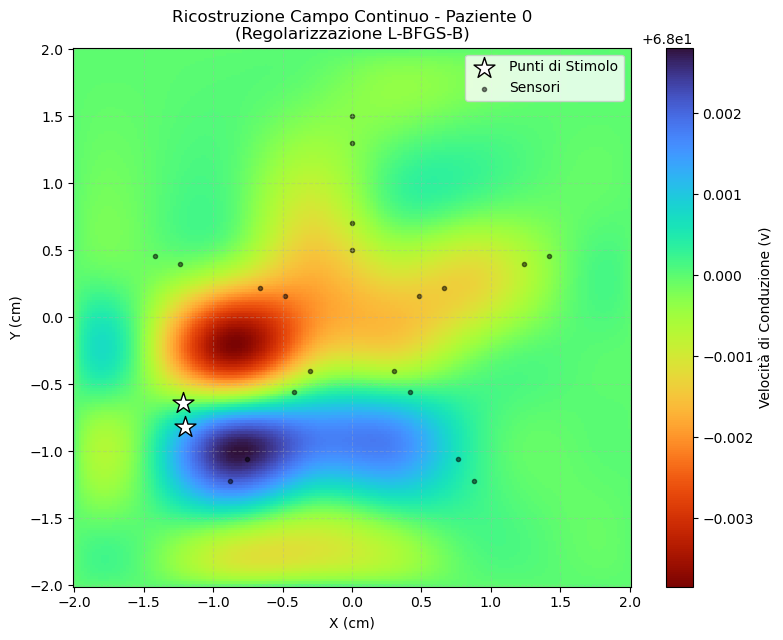

In [ ]:
# ==========================================
# CELLA 5: OTTIMIZZAZIONE E CREAZIONE field16
# ==========================================
TARGET_PATIENT = 0 # Cambia questo indice (0-24) per testare casi diversi

print(f"🚀 Avvio ricostruzione per il Paziente {TARGET_PATIENT}...")

# Funzione wrapper per l'ottimizzatore (congela l'indice del paziente)
def objective_wrapper(v_coarse_flat):
    return evaluate_patient(TARGET_PATIENT, v_coarse_flat, lambda_reg=10.0)

# Inizializzazione e Limiti (N_coarse = 8, totale 64 parametri)
initial_guess = np.full((N_coarse, N_coarse), EST_V_BASE).flatten()
bounds = [(10.0, 100.0) for _ in range(N_coarse * N_coarse)]

# Ottimizzazione L-BFGS-B
res_field = minimize(
    objective_wrapper, 
    initial_guess, 
    method='L-BFGS-B', 
    bounds=bounds, 
    options={'maxiter': 60, 'ftol': 1e-3, 'disp': True}
)

# 1. Generazione Mappa Densa per il Plot visivo e la fisica (201x201)
final_speed_map = generate_dense_field(res_field.x)

# ---------------------------------------------------------
# 2. GENERAZIONE field16 (Griglia 16x16 richiesta dal notebook)
# ---------------------------------------------------------
# Creiamo gli assi per la griglia 16x16
x_16 = np.linspace(-2.0, 2.0, 16)

# Ricostruiamo la matrice di controllo ottimizzata 8x8
v_coarse_2d = res_field.x.reshape((N_coarse, N_coarse))

# Usiamo la spline per estrarre esattamente 16x16 punti
interpolator_16 = RectBivariateSpline(x_coarse, x_coarse, v_coarse_2d)
field16 = interpolator_16(x_16, x_16)

# Troncamento di sicurezza
field16 = np.clip(field16, 5.0, 150.0)

print(f"✅ Ottimizzazione conclusa.")
print(f"✅ Variabile 'field16' generata con successo. Dimensioni: {field16.shape}")

# ---------------------------------------------------------
# 3. Visualizzazione
# ---------------------------------------------------------
plt.figure(figsize=(9, 7))
mesh_plot = plt.pcolormesh(X_mesh_vel, Y_mesh_vel, final_speed_map, shading='auto', cmap='turbo_r')
plt.colorbar(mesh_plot, label='Velocità di Conduzione (v)')

# Punti di stimolo
plt.scatter(focal_points[TARGET_PATIENT][:, 0], focal_points[TARGET_PATIENT][:, 1], 
            c='white', marker='*', s=250, edgecolor='black', label='Punti di Stimolo')

# Sensori
plt.scatter(X_mesh_vel[idx_vel[:, 0], idx_vel[:, 1]], 
            Y_mesh_vel[idx_vel[:, 0], idx_vel[:, 1]], 
            c='black', marker='.', alpha=0.5, label='Sensori')

plt.title(f"Ricostruzione Campo Continuo - Paziente {TARGET_PATIENT}\n(Griglia di output pronta per la valutazione)")
plt.xlabel('X (cm)')
plt.ylabel('Y (cm)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

In [ ]:
def GroupSolutionCP3( signals_event , x_0, y_0, t_0, x_1, y_1 , t_1 ):

    
    # your implementation
    #field16 = #
    
    return field16